In [280]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score, roc_auc_score
from xgboost import XGBRegressor
from catboost import CatBoostRegressor


In [201]:
df = pd.read_csv('/Users/jaydipchauhan/Documents/DS/Projects/playground-series-Airline/train.csv')

In [202]:
df.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,0,36,694,4,4,4,3,1,4,1,...,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
1,1,56,651,5,5,5,5,5,4,4,...,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,True
2,2,31,1371,3,4,2,5,3,3,3,...,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
3,3,10,1616,3,5,3,3,3,3,3,...,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
4,4,23,481,3,4,3,4,5,3,5,...,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,False


In [203]:
df.shape

(699635, 23)

In [204]:
df.isna().mean().sum() * 100

np.float64(0.041736048082214296)

In [205]:
df_copy = df.copy()
df = df.dropna()

In [206]:
df.isna().sum().sum()

np.int64(0)

In [207]:
df.duplicated().sum()

np.int64(0)

In [208]:
df.select_dtypes(['object'])

,Gender,Customer Type,Type of Travel,Class
0,Female,Loyal Customer,Personal Travel,Eco
1,Male,Loyal Customer,Business travel,Business
2,Female,Loyal Customer,Personal Travel,Eco
3,Male,Loyal Customer,Personal Travel,Eco
4,Female,disloyal Customer,Business travel,Eco
...,...,...,...,...
699630,Female,Loyal Customer,Business travel,Eco
699631,Female,disloyal Customer,Business travel,Eco
699632,Male,Loyal Customer,Business travel,Business
699633,Female,Loyal Customer,Business travel,Eco


In [209]:
df.columns

Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class', 'satisfaction'],
      dtype='object')

In [210]:
df['Gender'].unique()

array(['Female', 'Male'], dtype=object)

In [211]:
df['Customer Type'].unique()

array(['Loyal Customer', 'disloyal Customer'], dtype=object)

In [212]:
df['Class'].unique()

array(['Eco', 'Business', 'Eco Plus'], dtype=object)

In [213]:
df.describe()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
count,699343.000000,699343.000000,699343.000000,699343.000000,699343.000000,699343.000000,699343.000000,699343.000000,699343.000000,699343.000000,699343.000000,699343.000000,699343.000000,699343.000000,699343.000000,699343.000000,699343.000000,699343.000000
mean,349820.496269,39.002531,1353.798525,2.778757,3.156138,2.813262,3.013706,3.265625,3.364226,3.568968,3.453916,3.517436,3.472831,3.805426,3.420329,3.380398,1.173596,1.134280
std,201968.837438,13.800828,954.450464,1.280397,1.475381,1.329513,1.253994,1.300163,1.288479,1.275310,1.308135,1.238466,1.271748,1.079181,1.210601,1.277823,5.964274,5.749304
min,0.000000,7.000000,67.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,174909.500000,27.000000,631.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,3.000000,2.000000,3.000000,2.000000,3.000000,3.000000,2.000000,0.000000,0.000000
50%,349830.000000,40.000000,954.000000,3.000000,3.000000,3.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,0.000000,0.000000
75%,524728.500000,50.000000,1814.000000,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,5.000000,4.000000,5.000000,5.000000,4.000000,4.000000,0.000000,0.000000
max,699634.000000,85.000000,4983.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,489.000000,491.000000


In [214]:
df.sample(10)

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
202459,202459,30,2125,2,1,2,2,4,4,4,...,4,3,4,0,0.0,Female,Loyal Customer,Business travel,Business,True
355422,355422,29,533,3,3,3,3,4,4,4,...,4,2,4,0,0.0,Male,Loyal Customer,Business travel,Business,True
64074,64074,27,544,1,1,1,3,2,1,2,...,4,3,2,0,0.0,Male,disloyal Customer,Business travel,Business,False
23023,23023,61,2562,5,5,5,5,4,5,4,...,5,3,3,0,0.0,Female,Loyal Customer,Business travel,Business,True
50938,50938,42,409,3,5,3,3,2,4,4,...,4,3,4,0,0.0,Female,Loyal Customer,Personal Travel,Eco,False
621711,621711,37,872,3,1,3,3,5,4,5,...,3,4,5,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
415086,415086,70,590,2,4,3,1,3,3,3,...,4,3,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,False
138286,138286,40,944,2,5,5,5,2,2,2,...,3,3,2,0,0.0,Male,Loyal Customer,Business travel,Eco,False
23475,23475,44,3942,5,5,5,5,2,5,5,...,3,3,4,0,0.0,Male,Loyal Customer,Business travel,Business,True
491673,491673,31,101,4,5,5,5,4,4,4,...,4,4,4,0,2.0,Female,Loyal Customer,Business travel,Eco,True


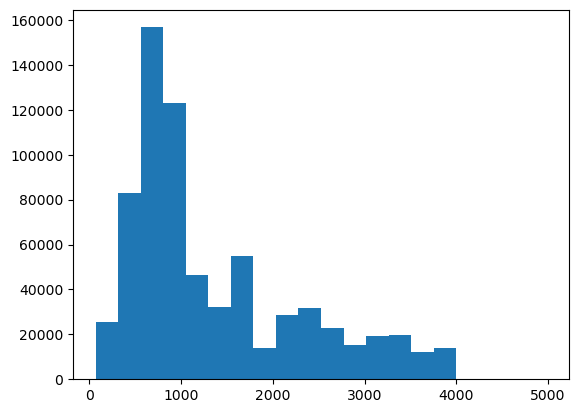

In [215]:
plt.hist(df['Flight Distance'], bins = 20)
plt.show()

In [216]:
bins = np.linspace(67, 4983, 21)

print(bins)

[  67.   312.8  558.6  804.4 1050.2 1296.  1541.8 1787.6 2033.4 2279.2
 2525.  2770.8 3016.6 3262.4 3508.2 3754.  3999.8 4245.6 4491.4 4737.2
 4983. ]


In [217]:
df['Flight Distance bins'] = pd.cut(df['Flight Distance'], bins = bins, include_lowest=True)
df = df.drop('Flight Distance', axis =1)
df['Age_Group'] = pd.cut(df['Age'], bins = [0, 10, 18, 30, 60, 100], labels = ['Children', 'Young Adults', 'Adults', 'Mature', 'Seniors']) 
df = df.drop('Age', axis=1)
df['Satisfaction_target'] = df['satisfaction'].astype(int)
df = df.drop('satisfaction', axis = 1)

In [218]:
# plt.hist(df['Age'], bins = 5)

In [219]:
# df['Age'].describe()

In [220]:
df.head()

,id,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,...,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,Flight Distance bins,Age_Group,Satisfaction_target
0,0,4,4,4,3,1,4,1,1,3,...,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,"(558.6, 804.4]",Mature,0
1,1,5,5,5,5,5,4,4,5,5,...,3,0,0.0,Male,Loyal Customer,Business travel,Business,"(558.6, 804.4]",Mature,1
2,2,3,4,2,5,3,3,3,3,4,...,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,"(1296.0, 1541.8]",Mature,0
3,3,3,5,3,3,3,3,3,3,4,...,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,"(1541.8, 1787.6]",Children,0
4,4,3,4,3,4,5,3,5,5,5,...,5,5,0.0,Female,disloyal Customer,Business travel,Eco,"(312.8, 558.6]",Adults,0


In [221]:


x = df.drop(['id', 'Satisfaction_target'], axis = 1)
y = df['Satisfaction_target']
x_non_test, x_test, y_non_test, y_test = train_test_split(x, y, test_size=0.3, shuffle=True, random_state=0)
x_train, x_valid, y_train, y_valid = train_test_split(x_non_test, y_non_test, test_size=0.5, shuffle=True, random_state=0)

In [249]:


num_cols = x.select_dtypes(include=np.number).columns.to_list()
cat_cols = x.select_dtypes(exclude=np.number).columns.to_list()

scaler = StandardScaler()
encoder = OneHotEncoder(handle_unknown='ignore')

preprocessor = ColumnTransformer([
    ('num', scaler, num_cols),
    ('cat', encoder, cat_cols)
])

model = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=300,
    max_depth=None,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=1.0,
    bootstrap=True,
    max_samples=0.8,
    random_state=42,
    n_jobs=-1
    ))
])

model.fit(x_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [253]:


y_train_pred = model.predict(x_train)
print(f'Training MSE: {mean_squared_error(y_train, y_train_pred)}')
print(f'Training R2: {r2_score(y_train, y_train_pred)}')
print(f'Training ROC_AUC: {roc_auc_score(y_train, y_train_pred)}')

y_valid_pred = model.predict(x_valid)
print(f'Valdiation MSE: {mean_squared_error(y_valid, y_valid_pred)}')
print(f'Valdiation R2: {r2_score(y_valid, y_valid_pred)}')
print(f'Valdiation ROC_AUC: {roc_auc_score(y_valid, y_valid_pred)}')

y_test_pred = model.predict(x_test)
print(f'Test MSE: {mean_squared_error(y_test, y_test_pred)}')
print(f'Test R2: {r2_score(y_test, y_test_pred)}')
print(f'Test ROC_AUC: {roc_auc_score(y_test, y_test_pred)}')




Training MSE: 0.03133318686062404
Training R2: 0.8729581775452262
Training ROC_AUC: 0.9950821227687563
Valdiation MSE: 0.06572107264425954
Valdiation R2: 0.7337984243122783
Valdiation ROC_AUC: 0.9520496696189338
Test MSE: 0.06555122554094182
Test R2: 0.7345596593100786
Test ROC_AUC: 0.9524681376510835


In [278]:
model_xgboost = Pipeline([
    ('preprocessor', preprocessor),
    ('model', XGBRegressor(
    n_estimators=1000,
    max_depth=6,
    learning_rate=0.03,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_alpha=0.1,
    reg_lambda=1.0,
    objective="reg:squarederror",
    eval_metric="rmse",
    random_state=42,
    n_jobs=-1
)
)]
)

model_xgboost.fit(x_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [266]:
y_train_pred = model_xgboost.predict(x_train)
print(f'Training MSE: {mean_squared_error(y_train, y_train_pred)}')
print(f'Training R2: {r2_score(y_train, y_train_pred)}')
print(f'Training ROC_AUC: {roc_auc_score(y_train, y_train_pred)}')

y_valid_pred = model_xgboost.predict(x_valid)
print(f'Valdiation MSE: {mean_squared_error(y_valid, y_valid_pred)}')
print(f'Valdiation R2: {r2_score(y_valid, y_valid_pred)}')
print(f'Valdiation ROC_AUC: {roc_auc_score(y_valid, y_valid_pred)}')

y_test_pred = model_xgboost.predict(x_test)
print(f'Test MSE: {mean_squared_error(y_test, y_test_pred)}')
print(f'Test R2: {r2_score(y_test, y_test_pred)}')
print(f'Test ROC_AUC: {roc_auc_score(y_test, y_test_pred)}')

Training MSE: 0.059503644704818726
Training R2: 0.758739709854126
Training ROC_AUC: 0.9656887692534101
Valdiation MSE: 0.06326712667942047
Valdiation R2: 0.743738055229187
Valdiation ROC_AUC: 0.9558559250737665
Test MSE: 0.06319575011730194
Test R2: 0.7440978288650513
Test ROC_AUC: 0.9562665848242724


In [281]:
model_catboost = Pipeline([
    ("preprocessor", preprocessor),
    ("model", CatBoostRegressor(
        iterations=1000,
        depth=6,
        learning_rate=0.03,
        loss_function="RMSE",
        eval_metric="RMSE",
        random_seed=42,
        verbose=100,
        allow_writing_files=False
    ))
])

# Train model
model_catboost.fit(x_train, y_train)

0:	learn: 0.4869672	total: 64.9ms	remaining: 1m 4s
100:	learn: 0.2687111	total: 690ms	remaining: 6.14s
200:	learn: 0.2609549	total: 1.25s	remaining: 4.97s
300:	learn: 0.2572988	total: 1.81s	remaining: 4.21s
400:	learn: 0.2552641	total: 2.38s	remaining: 3.55s
500:	learn: 0.2538672	total: 2.96s	remaining: 2.95s
600:	learn: 0.2528634	total: 3.55s	remaining: 2.36s
700:	learn: 0.2521614	total: 4.13s	remaining: 1.76s
800:	learn: 0.2516974	total: 4.66s	remaining: 1.16s
900:	learn: 0.2512568	total: 5.2s	remaining: 571ms
999:	learn: 0.2508815	total: 5.76s	remaining: 0us


,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [282]:

y_train_pred = model_catboost.predict(x_train)

print(f'Training MSE: {mean_squared_error(y_train, y_train_pred)}')
print(f'Training R2: {r2_score(y_train, y_train_pred)}')
print(f'Training ROC_AUC: {roc_auc_score(y_train, y_train_pred)}')


y_valid_pred = model_catboost.predict(x_valid)

print(f'Validation MSE: {mean_squared_error(y_valid, y_valid_pred)}')
print(f'Validation R2: {r2_score(y_valid, y_valid_pred)}')
print(f'Validation ROC_AUC: {roc_auc_score(y_valid, y_valid_pred)}')


y_test_pred = model_catboost.predict(x_test)

print(f'Test MSE: {mean_squared_error(y_test, y_test_pred)}')
print(f'Test R2: {r2_score(y_test, y_test_pred)}')
print(f'Test ROC_AUC: {roc_auc_score(y_test, y_test_pred)}')


Training MSE: 0.06294154693346975
Training R2: 0.7448006528630704
Training ROC_AUC: 0.9591050202502063
Validation MSE: 0.06415714552934569
Validation R2: 0.7401330723254704
Validation ROC_AUC: 0.9555246356814644
Test MSE: 0.06410940298712521
Test R2: 0.7403981141481267
Test ROC_AUC: 0.956092201774924


In [294]:
test = pd.read_csv('/Users/jaydipchauhan/Documents/DS/Projects/playground-series-Airline/test.csv')

test_copy = test.copy()
test.head()

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
0,699635,25,1197,4,4,4,2,3,4,3,...,5,2,1,3,0,0.0,Female,disloyal Customer,Business travel,Eco
1,699636,36,829,5,5,5,5,5,4,5,...,2,4,3,5,0,0.0,Male,Loyal Customer,Business travel,Eco
2,699637,45,472,4,5,5,5,4,4,4,...,3,1,3,4,0,0.0,Male,Loyal Customer,Business travel,Eco
3,699638,45,762,2,2,2,5,3,2,3,...,4,4,4,3,0,0.0,Female,disloyal Customer,Business travel,Business
4,699639,34,594,1,2,1,1,2,1,2,...,4,2,1,2,0,0.0,Male,Loyal Customer,Personal Travel,Eco Plus


In [295]:
# Preprocessing

test['Flight Distance bins'] = pd.cut(
    test['Flight Distance'],
    bins=bins,
    include_lowest=True
)
test = test.drop('Flight Distance', axis=1)

test['Age_Group'] = pd.cut(
    test['Age'],
    bins=[0, 10, 18, 30, 60, 100],
    labels=['Children', 'Young Adults', 'Adults', 'Mature', 'Seniors']
)
test = test.drop('Age', axis=1)
test = test.drop('id', axis=1)

In [296]:
test[cat_cols]

,Gender,Customer Type,Type of Travel,Class,Flight Distance bins,Age_Group
0,Female,disloyal Customer,Business travel,Eco,"(1050.2, 1296.0]",Adults
1,Male,Loyal Customer,Business travel,Eco,"(804.4, 1050.2]",Mature
2,Male,Loyal Customer,Business travel,Eco,"(312.8, 558.6]",Mature
3,Female,disloyal Customer,Business travel,Business,"(558.6, 804.4]",Mature
4,Male,Loyal Customer,Personal Travel,Eco Plus,"(558.6, 804.4]",Mature
...,...,...,...,...,...,...
299839,Female,Loyal Customer,Business travel,Business,"(1541.8, 1787.6]",Mature
299840,Female,disloyal Customer,Business travel,Eco,"(1296.0, 1541.8]",Adults
299841,Male,Loyal Customer,Personal Travel,Eco,"(66.999, 312.8]",Mature
299842,Male,Loyal Customer,Personal Travel,Eco,"(558.6, 804.4]",Mature


In [297]:
test[num_cols]

,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
0,4,4,4,2,3,4,3,3,2,5,2,1,3,0,0.0
1,5,5,5,5,5,4,5,5,1,2,4,3,5,0,0.0
2,4,5,5,5,4,4,4,4,3,3,1,3,4,0,0.0
3,2,2,2,5,3,2,3,3,3,4,4,4,3,0,0.0
4,1,2,1,1,2,1,2,2,2,4,2,1,2,0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
299839,3,1,3,3,3,3,3,3,3,3,3,1,3,0,0.0
299840,3,3,3,4,3,3,3,2,1,2,3,5,3,0,0.0
299841,4,5,4,3,3,4,3,3,4,3,2,2,3,0,0.0
299842,3,5,3,2,4,3,5,5,4,4,4,4,5,4,0.0


In [303]:
test_pred_xgb = model_xgboost.predict(test)
test_pred_cat = model_catboost.predict(test)

In [316]:
blend_prob = 0.5 * test_pred_xgb + 0.5 * test_pred_cat

In [315]:
submission_ver7_blend = pd.DataFrame()

submission_ver7_blend['id'] = test_copy['id']
submission_ver7_blend['satisfaction'] = blend_prob

submission_ver7_blend.head()

submission_ver7_blend.to_csv('submission_ver7_blend.csv', index=False)

In [317]:
# Hyperparameter Tuning

In [321]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold


cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

param_distributions = {
    "model__n_estimators": [300, 500, 800, 1000, 1500],
    "model__max_depth": [3, 4, 5, 6, 8, 10],
    "model__learning_rate": [0.01, 0.02, 0.03, 0.05, 0.08],
    "model__min_child_weight": [1, 3, 5, 7, 10],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "model__reg_alpha": [0, 0.01, 0.1, 0.5, 1],
    "model__reg_lambda": [1, 2, 5, 10],
    "model__gamma": [0, 0.1, 0.3, 0.5]
}

search = RandomizedSearchCV(
    estimator=model_xgboost,
    param_distributions=param_distributions,
    n_iter=20,
    scoring="r2",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True
)

search.fit(x_train, y_train)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
[CV] END model__colsample_bytree=0.7, model__gamma=0.3, model__learning_rate=0.01, model__max_depth=3, model__min_child_weight=10, model__n_estimators=1500, model__reg_alpha=0.1, model__reg_lambda=2, model__subsample=0.9; total time=  19.5s
[CV] END model__colsample_bytree=0.7, model__gamma=0.3, model__learning_rate=0.01, model__max_depth=3, model__min_child_weight=10, model__n_estimators=1500, model__reg_alpha=0.1, model__reg_lambda=2, model__subsample=0.9; total time=  19.6s
[CV] END model__colsample_bytree=0.7, model__gamma=0.3, model__learning_rate=0.01, model__max_depth=3, model__min_child_weight=10, model__n_estimators=1500, model__reg_alpha=0.1, model__reg_lambda=2, model__subsample=0.9; total time=  19.8s
[CV] END model__colsample_bytree=0.9, model__gamma=0.5, model__learning_rate=0.01, model__max_depth=10, model__min_child_weight=5, model__n_estimators=1500, model__reg_alpha=0.1, model__reg_lambda=1, model__subsampl

,estimator,"Pipeline(step...=None, ...))])"
,param_distributions,"{'model__colsample_bytree': [0.7, 0.8, ...], 'model__gamma': [0, 0.1, ...], 'model__learning_rate': [0.01, 0.02, ...], 'model__max_depth': [3, 4, ...], ...}"
,n_iter,20
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,2
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [323]:
print("Best R2:", search.best_score_)
print("Best parameters:", search.best_params_)

best_xgb_regressor = search.best_estimator_

# Evaluate on your separate validation set
valid_predictions = best_xgb_regressor.predict(x_valid)

print(
    "Validation R2:",
    r2_score(y_valid, valid_predictions)
)

print(
    "Validation MSE:",
    np.mean((y_valid - valid_predictions) ** 2)
)

Best R2: 0.746744692325592
Best parameters: {'model__subsample': 0.7, 'model__reg_lambda': 10, 'model__reg_alpha': 0, 'model__n_estimators': 1500, 'model__min_child_weight': 10, 'model__max_depth': 10, 'model__learning_rate': 0.01, 'model__gamma': 0.3, 'model__colsample_bytree': 0.7}
Validation R2: 0.7461973428726196
Validation MSE: 0.06265996320849403


In [326]:
y_valid_pred = best_xgb_regressor.predict(x_valid)

print("Validation MSE:", mean_squared_error(y_valid, y_valid_pred))
print("Validation R²:", r2_score(y_valid, y_valid_pred))
print("Validation ROC-AUC:", roc_auc_score(y_valid, y_valid_pred))

Validation MSE: 0.06265996396541595
Validation R²: 0.7461973428726196
Validation ROC-AUC: 0.956510367766386


In [ ]:
test_pred_search_xgb = best_xgb_regressor.predict(test)

In [327]:
submission_ver8_search_xgb = pd.DataFrame()

submission_ver8_search_xgb['id'] = test_copy['id']
submission_ver8_search_xgb['satisfaction'] = blend_prob

submission_ver8_search_xgb.head()

submission_ver8_search_xgb.to_csv('submission_ver8_search_xgb.csv', index=False)

In [331]:
df.corr(numeric_only=True) > 0.6

,id,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Satisfaction_target
id,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
Inflight wifi service,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False
Departure/Arrival time convenient,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False
Ease of Online booking,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False
Gate location,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False
Food and drink,False,False,False,False,False,True,False,True,True,False,False,False,False,True,False,False,False
Online boarding,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False
Seat comfort,False,False,False,False,False,True,False,True,True,False,False,False,False,True,False,False,False
Inflight entertainment,False,False,False,False,False,True,False,True,True,False,False,False,False,True,False,False,False
On-board service,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False


<Axes: >

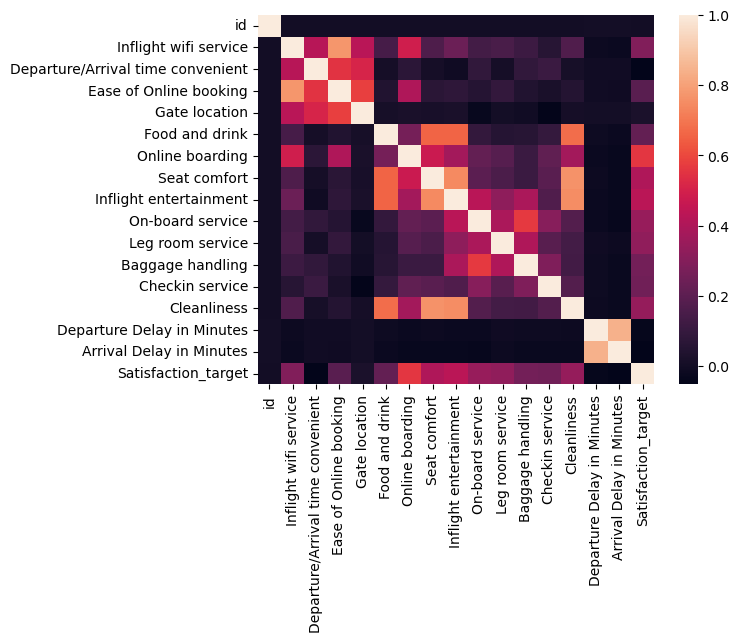

In [332]:
import seaborn as sns

sns.heatmap(df.corr(numeric_only=True))

In [ ]:

best_cat = search.best_estimator_

valid_predictions = best_cat.predict(X_valid_cb)

print(
    "Validation ROC-AUC:",
    roc_auc_score(y_valid, valid_predictions)
)